In [376]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [377]:
df = pd.read_csv("../data/cleaned/layoffs_cleaned.csv")

In [378]:
df['date'] = pd.to_datetime(df['date'])

In [379]:
df['date'].dtype

dtype('<M8[us]')

In [380]:
#setting one consistent chart style
sns.set_theme(style="whitegrid",palette="deep")

sns.set_theme() → Sets the overall appearance of our charts.

style="whitegrid" → Gives charts a white background with light grid lines.

palette="deep" → Uses a consistent set of colors for charts.

creating second dataframe 

We need two DataFrames because our project answers two different questions:
1. How many people were laid off?
2. How many layoff events happened?

during data cleaning we created the column of size_known which tells us if True Layoff count is available if False then Layoff count is not available

In [381]:
df_size = df[df['size_known']==True].copy()

In [382]:
df.shape

(4670, 14)

In [383]:
df_size.shape

(3044, 14)

# Data Analysis 

# 1.How have layoffs changed over time?

two different measurements:
- Total employees laid off — how many people lost their jobs?
- Number of layoff events — how many layoff records were reported?


Yearly layoffs - Total employees laid off per year - df_size

Yearly events -	Number of layoff records per year -	df

Monthly layoffs - Total employees laid off per month - df_size

Monthly events - Number of layoff records per month - df


### Part A — Yearly analysis

In [384]:
yearly_layoffs = (df_size.groupby('year')['total_laid_off'].sum().reset_index())

- df_size - only recors with known employee count
- .groupby('year') - Groups records belonging to the same year
- ['total_laid_off'] → Selects the employee-count column.
- .sum() → Adds all employee counts within each year.
- .reset_index() → Converts the grouped result back into a normal DataFrame

In [385]:
yearly_layoffs

,year,total_laid_off
0,2020,80998.0
1,2021,15823.0
2,2022,164249.0
3,2023,264660.0
4,2024,152922.0
5,2025,122606.0
6,2026,144171.0


In [386]:
yearly_events = (df.groupby('year').size().reset_index(name='total_events'))

In [387]:
yearly_events

,year,total_events
0,2020,635
1,2021,44
2,2022,1227
3,2023,1389
4,2024,635
5,2025,333
6,2026,407


Chart 1 - Total layoffs per year

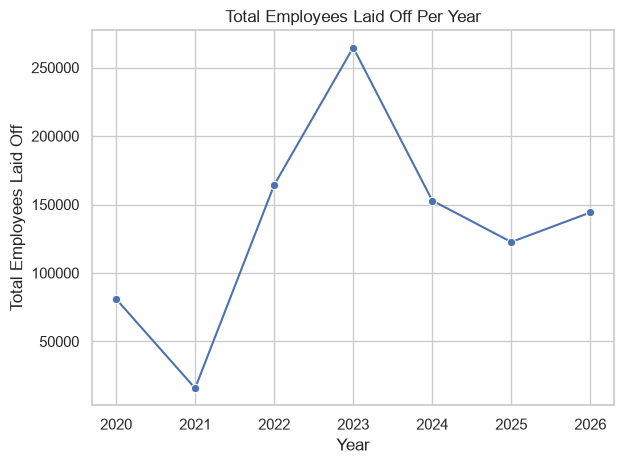

In [388]:
sns.lineplot(
    data=yearly_layoffs,
    x='year',
    y='total_laid_off',
    marker='o'
)
plt.title('Total Employees Laid Off Per Year')
plt.xlabel('Year')
plt.ylabel('Total Employees Laid Off')
plt.xticks(yearly_layoffs['year'])
plt.tight_layout()

plt.savefig('../visualizations/01_layoffs_by_year.png',
            dpi=150, bbox_inches='tight')

plt.show()


Chart 2 - Layoffs events per year

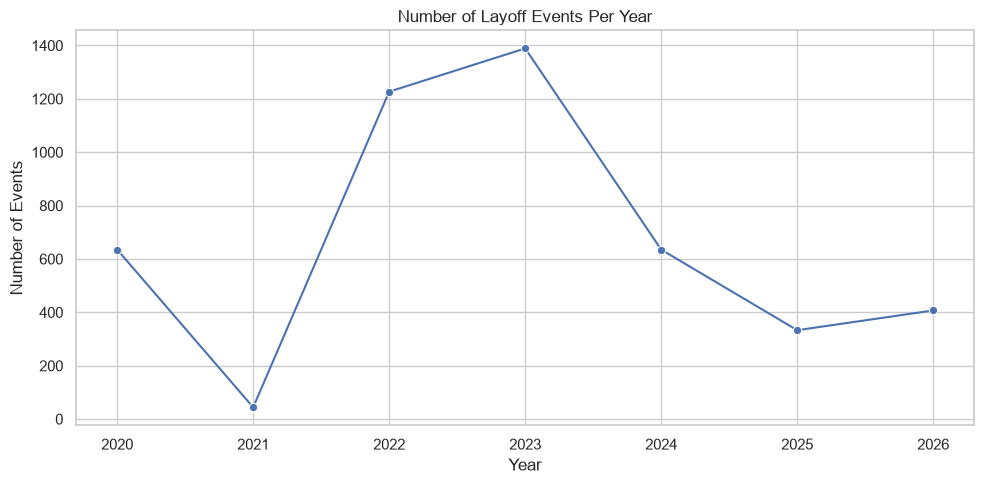

In [389]:
plt.figure(figsize=(10,5))
sns.lineplot(
    data=yearly_events,
    x='year',
    y='total_events',
    marker='o'
)
plt.title('Number of Layoff Events Per Year')
plt.xlabel('Year')
plt.ylabel('Number of Events')
plt.xticks(yearly_events['year'])
plt.tight_layout()

plt.savefig('../visualizations/02_events_by_year.png',
            dpi=150, bbox_inches='tight')

plt.show()

### Part B — Monthly analysis

Total employees laid off per month

In [390]:
monthly_layoffs = (
    df_size.groupby(['year','month'])['total_laid_off'].sum().reset_index()
)

In [391]:
monthly_layoffs

,year,month,total_laid_off
0,2020,3,9628.0
1,2020,4,26710.0
2,2020,5,25804.0
3,2020,6,7627.0
4,2020,7,7112.0
...,...,...,...
75,2026,7,11000.0
76,2026,8,3555.0
77,2026,9,6947.0
78,2026,10,6150.0


In [392]:
monthly_events = (
    df.groupby(['year', 'month'])
    .size()
    .reset_index(name='total_events')
)

In [393]:
monthly_events

,year,month,total_events
0,2020,3,121
1,2020,4,270
2,2020,5,110
3,2020,6,49
4,2020,7,27
...,...,...,...
76,2026,7,46
77,2026,8,43
78,2026,9,33
79,2026,10,33


In [394]:
monthly_layoffs['month_date'] = pd.to_datetime(
    monthly_layoffs[['year', 'month']].assign(day=1)
)

monthly_events['month_date'] = pd.to_datetime(
    monthly_events[['year', 'month']].assign(day=1)
)

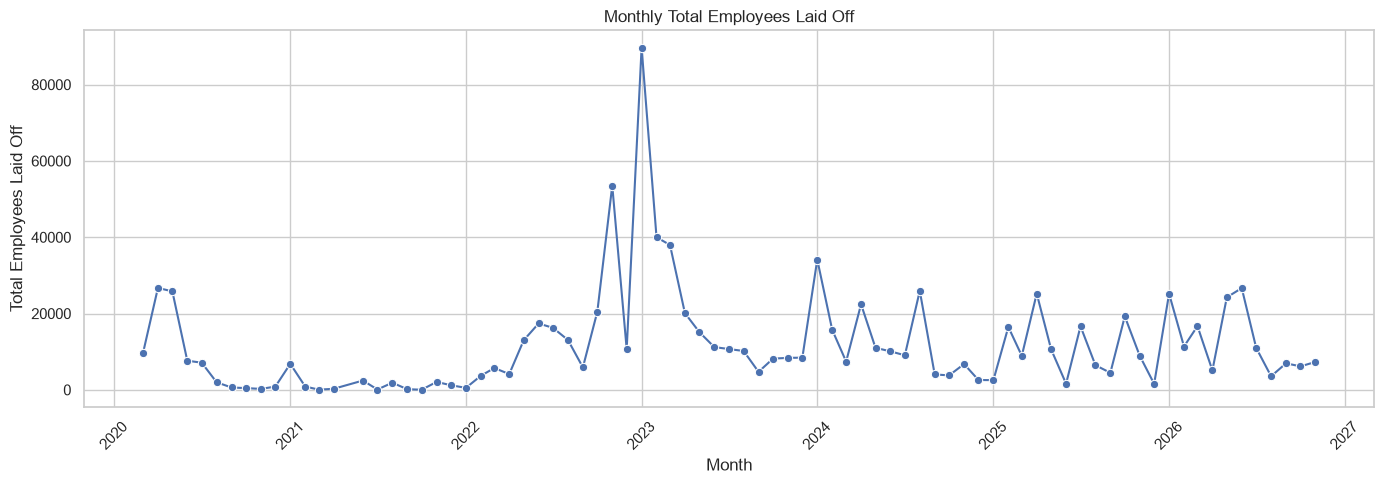

In [395]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_layoffs,
    x='month_date',
    y='total_laid_off',
    marker='o'
)

plt.title('Monthly Total Employees Laid Off')
plt.xlabel('Month')
plt.ylabel('Total Employees Laid Off')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../visualizations/03_monthly_layoffs.png',
            dpi=150, bbox_inches='tight')

plt.show()

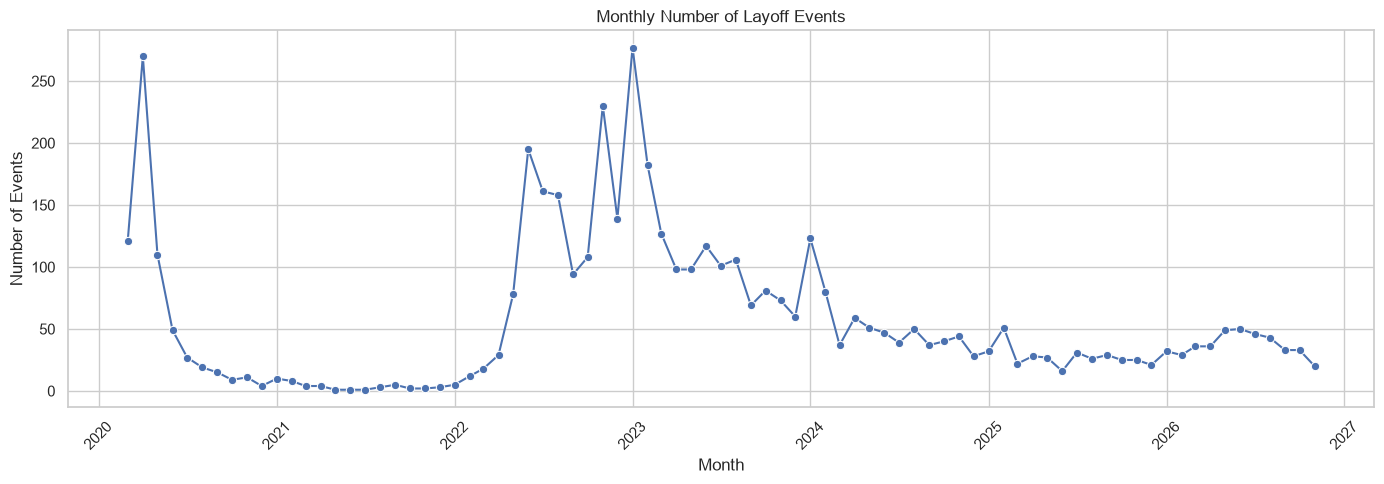

In [396]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_events,
    x='month_date',
    y='total_events',
    marker='o'
)

plt.title('Monthly Number of Layoff Events')
plt.xlabel('Month')
plt.ylabel('Number of Events')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../visualizations/04_monthly_events.png',
            dpi=150, bbox_inches='tight')

plt.show()

In [397]:
yearly_layoffs.loc[yearly_layoffs['total_laid_off'].idxmax()]

year                2023.0
total_laid_off    264660.0
Name: 3, dtype: float64

In [398]:
yearly_events.loc[yearly_events['total_events'].idxmax()]

year            2023
total_events    1389
Name: 3, dtype: int64

In [399]:
monthly_layoffs.loc[monthly_layoffs['total_laid_off'].idxmax()]

year                             2023
month                               1
total_laid_off                89709.0
month_date        2023-01-01 00:00:00
Name: 33, dtype: object

### Q1. Insights

1. The year with the highest total layoffs was **2023**, with **264,660 employees** laid off.
2. The year with the highest number of layoff events was **2023**, with **1,389 events**.
3. The highest monthly layoffs occurred in **January 2023**, with **89,709 employees** laid off.
4. 2020 and 2026 are partial years, so their totals should not be directly compared with complete years.

# Q2. Which industries were hit hardest?

1. Which industries lost the most employees?
2. Which industries experienced the most layoff events?

Calculate total employees laid off by industry

In [400]:
industry_layoffs = (df_size.groupby('industry')['total_laid_off'].sum().reset_index().sort_values('total_laid_off',ascending=False))

In [401]:
industry_layoffs

,industry,total_laid_off
20,Other,117130.0
24,Retail,110158.0
12,Hardware,107032.0
3,Consumer,100625.0
28,Transportation,70353.0
8,Finance,68531.0
10,Food,52297.0
13,Healthcare,40788.0
14,Infrastructure,25025.0
29,Travel,24398.0


In [402]:
top_10_industries = industry_layoffs.head(10)

In [403]:
top_10_industries

,industry,total_laid_off
20,Other,117130.0
24,Retail,110158.0
12,Hardware,107032.0
3,Consumer,100625.0
28,Transportation,70353.0
8,Finance,68531.0
10,Food,52297.0
13,Healthcare,40788.0
14,Infrastructure,25025.0
29,Travel,24398.0


creating horizontal bar chart

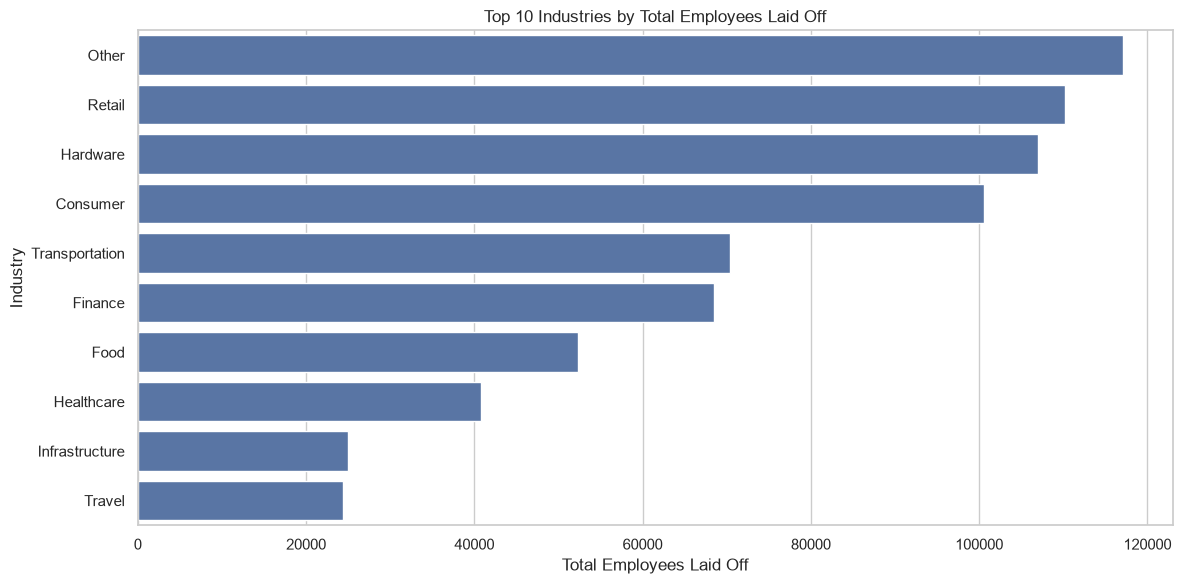

In [404]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_10_industries,
    x='total_laid_off',
    y='industry'
)
plt.title('Top 10 Industries by Total Employees Laid Off')
plt.xlabel('Total Employees Laid Off')
plt.ylabel('Industry')

plt.tight_layout()

plt.savefig(
    '../visualizations/05_top_10_industries_by_layoffs.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()



Group by industry and count events

In [405]:
industry_events = (
    df.groupby('industry')
    .size()
    .reset_index(name='total_events')
    .sort_values('total_events', ascending=False)
)

In [406]:
top_10_industry_events = industry_events.head(10)

In [407]:
top_10_industry_events

,industry,total_events
8,Finance,553
24,Retail,369
13,Healthcare,339
3,Consumer,322
20,Other,321
28,Transportation,277
10,Food,259
18,Marketing,226
4,Crypto,184
26,Security,171


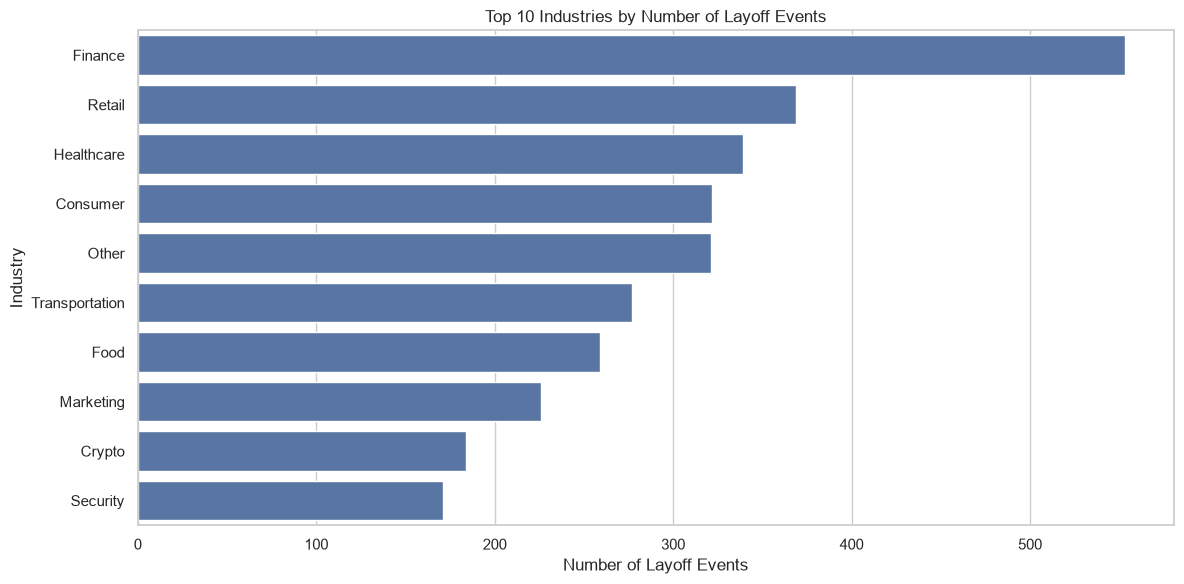

In [408]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_industry_events,
    x='total_events',
    y='industry'
)

plt.title('Top 10 Industries by Number of Layoff Events')
plt.xlabel('Number of Layoff Events')
plt.ylabel('Industry')

plt.tight_layout()

plt.savefig(
    '../visualizations/06_top_10_industries_by_events.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

Compare both rankings

In [409]:
industry_comparison = pd.merge(
    top_10_industries,
    top_10_industry_events,
    on='industry',
    how='outer'
)

In [410]:
industry_comparison

,industry,total_laid_off,total_events
0,Consumer,100625.0,322.0
1,Crypto,NaN,184.0
2,Finance,68531.0,553.0
3,Food,52297.0,259.0
4,Hardware,107032.0,NaN
5,Healthcare,40788.0,339.0
6,Infrastructure,25025.0,NaN
7,Marketing,NaN,226.0
8,Other,117130.0,321.0
9,Retail,110158.0,369.0


### Q2. Insights

1. The industry with the highest total employee layoffs was Other, with 117,130 employees laid off.
2. Finance recorded the highest number of layoff events, with 553 events.
3. Retail ranked highly in both total layoffs and number of events.
4. The rankings are not the same because some industries experience fewer but larger layoffs, while others experience more frequent layoff events.
5. Other is a catch-all category, not a specific industry. Although it recorded the highest total layoffs (117,130), it should not be described as the hardest-hit individual industry.
6. Hardware ranked third in total employees laid off (107,032), but did not appear in the top 10 industries by event count. This suggests its recorded layoffs were concentrated in fewer, larger events. Intel and Dell were among the companies contributing to the high Hardware total.

# Q3. Which companies laid off the most?

Which 10 companies laid off the most employees?

How many employees did those top 10 companies lay off?

What percentage of all recorded layoffs came from those top 10 companies?

Group layoffs by company

In [411]:
company_layoffs = (df_size.groupby('company')['total_laid_off'].sum().reset_index().sort_values('total_laid_off',ascending=False))

Get the top 10 companies

In [412]:
top_10_companies = company_layoffs.head(10)
top_10_companies

,company,total_laid_off
72,Amazon,59810.0
883,Intel,43167.0
1103,Meta,35700.0
1110,Microsoft,35355.0
493,Dell,23650.0
1241,Oracle,22294.0
368,Cisco,18521.0
1497,Salesforce,16744.0
1730,Tesla,14500.0
733,Google,13749.0


Visualize the top 10 companies

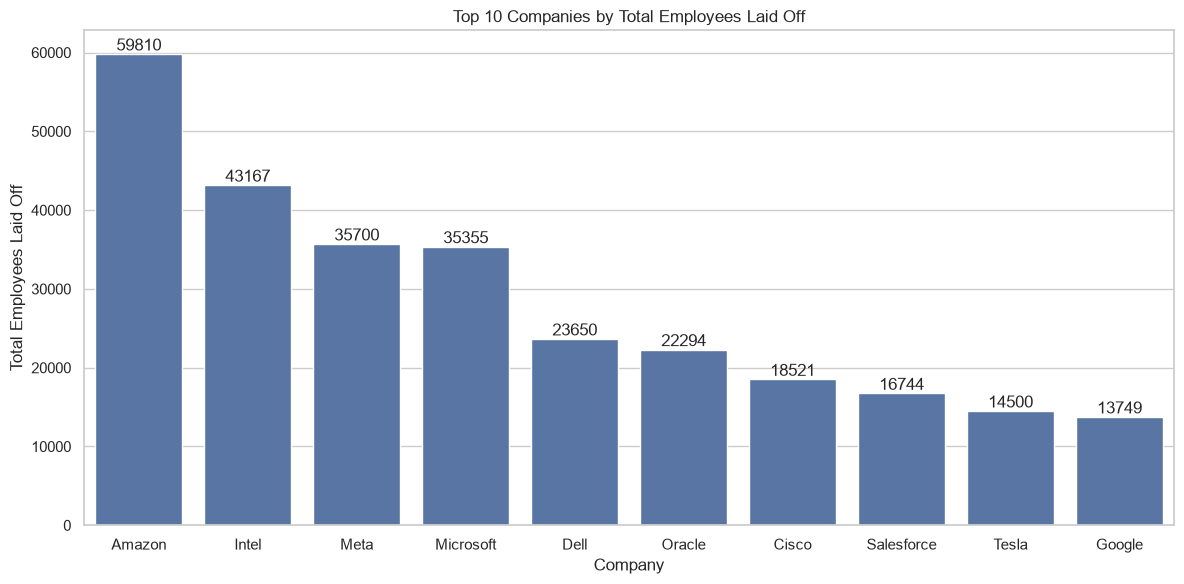

In [413]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=top_10_companies,
    x='company',
    y='total_laid_off'
)
plt.bar_label(ax.containers[0])

plt.title('Top 10 Companies by Total Employees Laid Off')
plt.xlabel('Company')
plt.ylabel('Total Employees Laid Off')

plt.tight_layout()

plt.savefig('../visualizations/07_top_10_companies_by_layoffs.png',
            dpi=150, bbox_inches='tight')

plt.show()

Calculate the percentage

In [414]:
total_layoffs = df_size['total_laid_off'].sum()

In [415]:
top_10_total = top_10_companies['total_laid_off'].sum()

In [416]:
top_10_percentage = (top_10_total / total_layoffs) * 100

top_10_percentage

np.float64(29.985329411304285)

In [417]:
print("Total recorded layoffs:", total_layoffs)
print("Top 10 companies' layoffs:", top_10_total)
print("Percentage of total layoffs by the Top 10 Companies:", round(top_10_percentage, 2), "%")

Total recorded layoffs: 945429.0
Top 10 companies' layoffs: 283490.0
Percentage of total layoffs by the Top 10 Companies: 29.99 %


### Q3. Insights

1. Amazon recorded the highest number of layoffs, with 59,810 employees.
2. Intel ranked second, followed by Meta and Microsoft.
3. The top 10 companies accounted for **29.99%** of all recorded layoffs.
4. This indicates that a significant share of recorded layoffs was concentrated among a relatively small number of companies.

# Q4. Which countries are most affected?

Top 10 countries by total employees laid off (including the United States).

Top 10 countries excluding the United States.

In [418]:
country_layoffs = (
    df_size.groupby('country')['total_laid_off']
    .sum()
    .reset_index()
    .sort_values('total_laid_off',ascending=False)
)

In [419]:
top_10_countries = country_layoffs.head(10)

top_10_countries

,country,total_laid_off
54,United States,669839.0
21,India,69939.0
18,Germany,32343.0
53,United Kingdom,22944.0
33,Netherlands,22375.0
47,Sweden,20579.0
6,Canada,17259.0
24,Israel,17079.0
4,Brazil,11939.0
1,Australia,9424.0


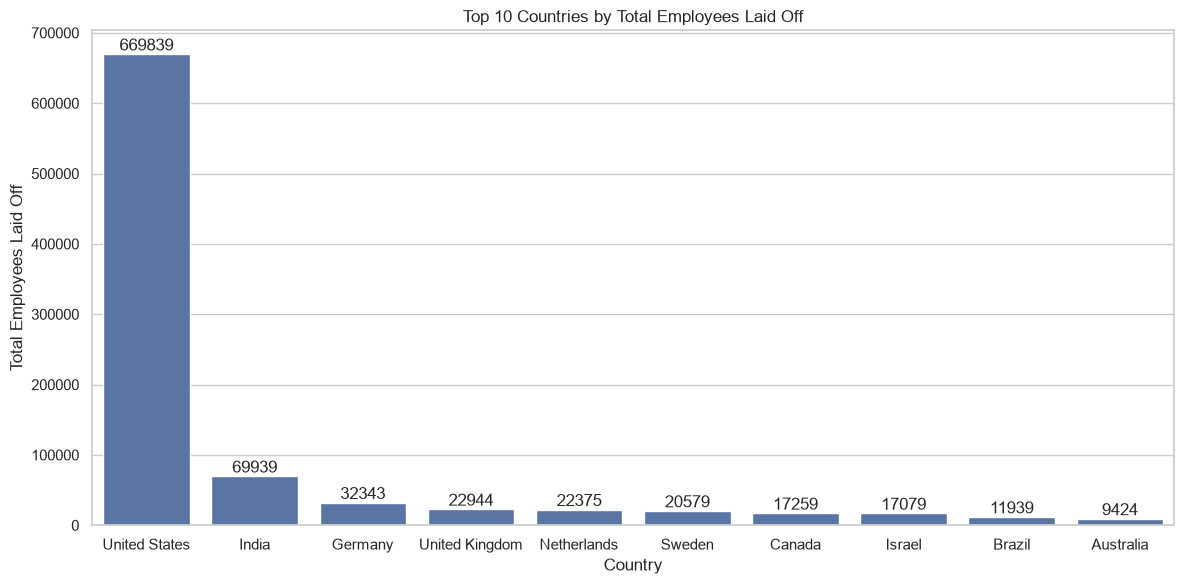

In [420]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=top_10_countries,
    x='country',
    y='total_laid_off'

)

plt.bar_label(ax.containers[0])

plt.title('Top 10 Countries by Total Employees Laid Off')
plt.xlabel('Country')
plt.ylabel('Total Employees Laid Off')

plt.tight_layout()

plt.savefig('../visualizations/08_top_10_countries_by_layoffs.png',
            dpi=150, bbox_inches='tight')

plt.show()

In [421]:
countries_without_us = country_layoffs[country_layoffs['country'] != 'United States']

In [422]:
top_10_countries_without_us = countries_without_us.head(10)

top_10_countries_without_us

,country,total_laid_off
21,India,69939.0
18,Germany,32343.0
53,United Kingdom,22944.0
33,Netherlands,22375.0
47,Sweden,20579.0
6,Canada,17259.0
24,Israel,17079.0
4,Brazil,11939.0
1,Australia,9424.0
9,China,8190.0


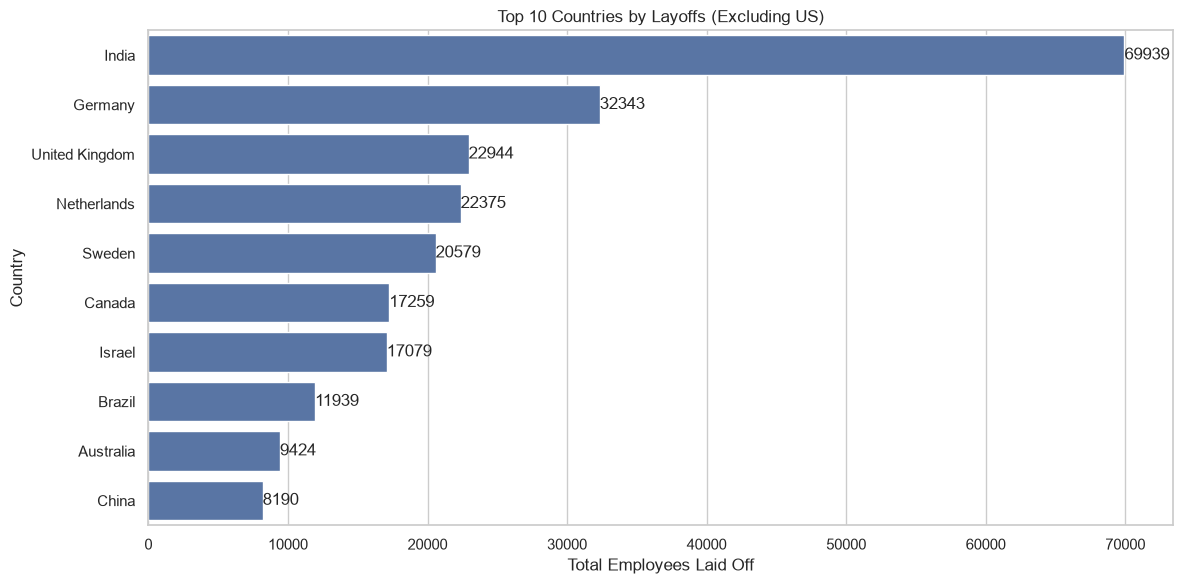

In [423]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_countries_without_us,
    x='total_laid_off',
    y='country'
)

ax.bar_label(ax.containers[0])

plt.title('Top 10 Countries by Layoffs (Excluding US)')
plt.xlabel('Total Employees Laid Off')
plt.ylabel('Country')

plt.tight_layout()

plt.savefig('../visualizations/09_top_10_countries_excluding_us.png',
            dpi=150, bbox_inches='tight')

plt.show()

### Q4. Insights

1. The United States recorded the highest total number of employee layoffs, with **669,839 employees**, accounting for approximately **70.9%** of all recorded layoffs in the dataset.
2. India recorded **69,939 layoffs**, representing approximately **7.4%** of all recorded layoffs, making it the second-largest contributor.
3. The United States accounts for a significantly larger share of recorded layoffs than any other country, highlighting its dominance in the overall country comparison.
4. Excluding the United States makes it easier to compare the remaining countries and understand their relative contributions.
5. The second chart highlights the countries with the highest recorded layoffs outside the United States.

**Note:** These percentages are calculated using 945,429 total recorded layoffs in the dataset. They represent the distribution of recorded layoffs, not necessarily the distribution of all real-world layoffs.

# Q5. Does company stage matter?

we're comparing company funding stages (such as Seed, Series A, Series B, IPO, etc.) against:

1. Layoff size: How many employees were laid off at each stage.

2. Number of events: How many layoff records each stage has.

We'll use the median instead of the mean because a few extremely large layoffs can pull the average upwards.

Calculate median layoffs by stage

In [424]:
stage_layoffs = (
    df_size.groupby('stage')['total_laid_off']
    .median()
    .reset_index()
    .sort_values('total_laid_off',ascending=False)
)
stage_layoffs
#median() — finds the middle layoff count for each stage

,stage,total_laid_off
12,Series I,300.0
13,Series J,250.0
1,Post-IPO,200.0
11,Series H,185.0
10,Series G,150.0
9,Series F,112.5
2,Private Equity,110.0
0,Acquired,100.0
14,Subsidiary,100.0
8,Series E,95.0


Calculate the number of layoff events by stage

In [425]:
stage_events = (
    df.groupby('stage')
    .size()
    .reset_index(name='total_events')
    .sort_values('total_events', ascending=False)
)

stage_events
#size() — counts the number of rows in each group.

,stage,total_events
1,Post-IPO,1140
15,Unknown,788
5,Series B,499
6,Series C,461
0,Acquired,427
7,Series D,369
4,Series A,278
8,Series E,213
3,Seed,162
9,Series F,129


Combine both results

In [458]:
stage_record_counts = (
    df_size.groupby('stage')
    .size()
    .reset_index(name='size_known_records')
)

stage_comparison = pd.merge(
    stage_layoffs,
    stage_events,
    on='stage',
    how='left'
)

stage_comparison = stage_comparison.sort_values(
    'total_laid_off',
    ascending=False
)

stage_comparison

,stage,total_laid_off,total_events
0,Series I,300.0,10
1,Series J,250.0,12
2,Post-IPO,200.0,1140
3,Series H,185.0,36
4,Series G,150.0,29
5,Series F,112.5,129
6,Private Equity,110.0,86
7,Acquired,100.0,427
8,Subsidiary,100.0,31
9,Series E,95.0,213


Chart — Median layoffs by company stage

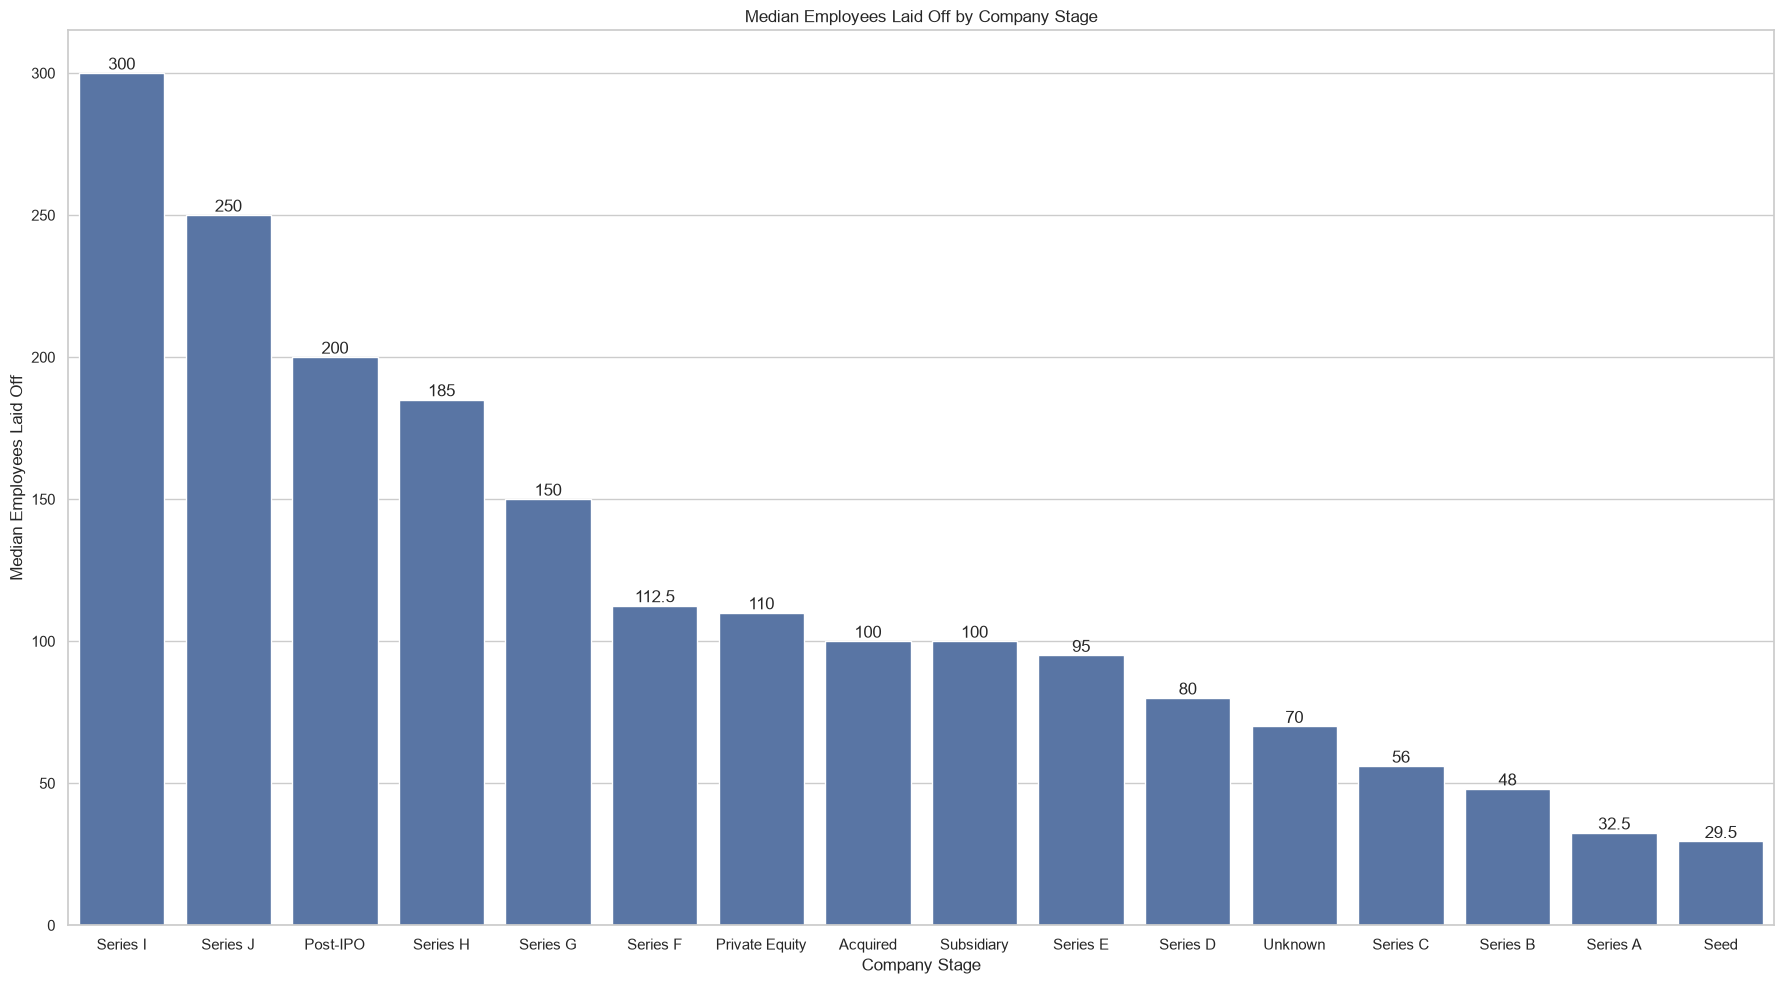

In [427]:
plt.figure(figsize=(18, 10))

ax = sns.barplot(
    data=stage_layoffs,
    x='stage',
    y='total_laid_off'
)

plt.bar_label(ax.containers[0])

plt.title('Median Employees Laid Off by Company Stage')
plt.xlabel('Company Stage')
plt.ylabel('Median Employees Laid Off')

plt.tight_layout()

plt.savefig('../visualizations/10_median_layoffs_by_stage.png',
            dpi=150, bbox_inches='tight')

plt.show()

It shows which company stages appear most frequently in the dataset's layoff records. A stage can have many events but a relatively low median layoff size.

Check whether a log scale is needed

In [ ]:
stage_layoffs['total_laid_off'].describe()

np.float64(1.0531602898633423)

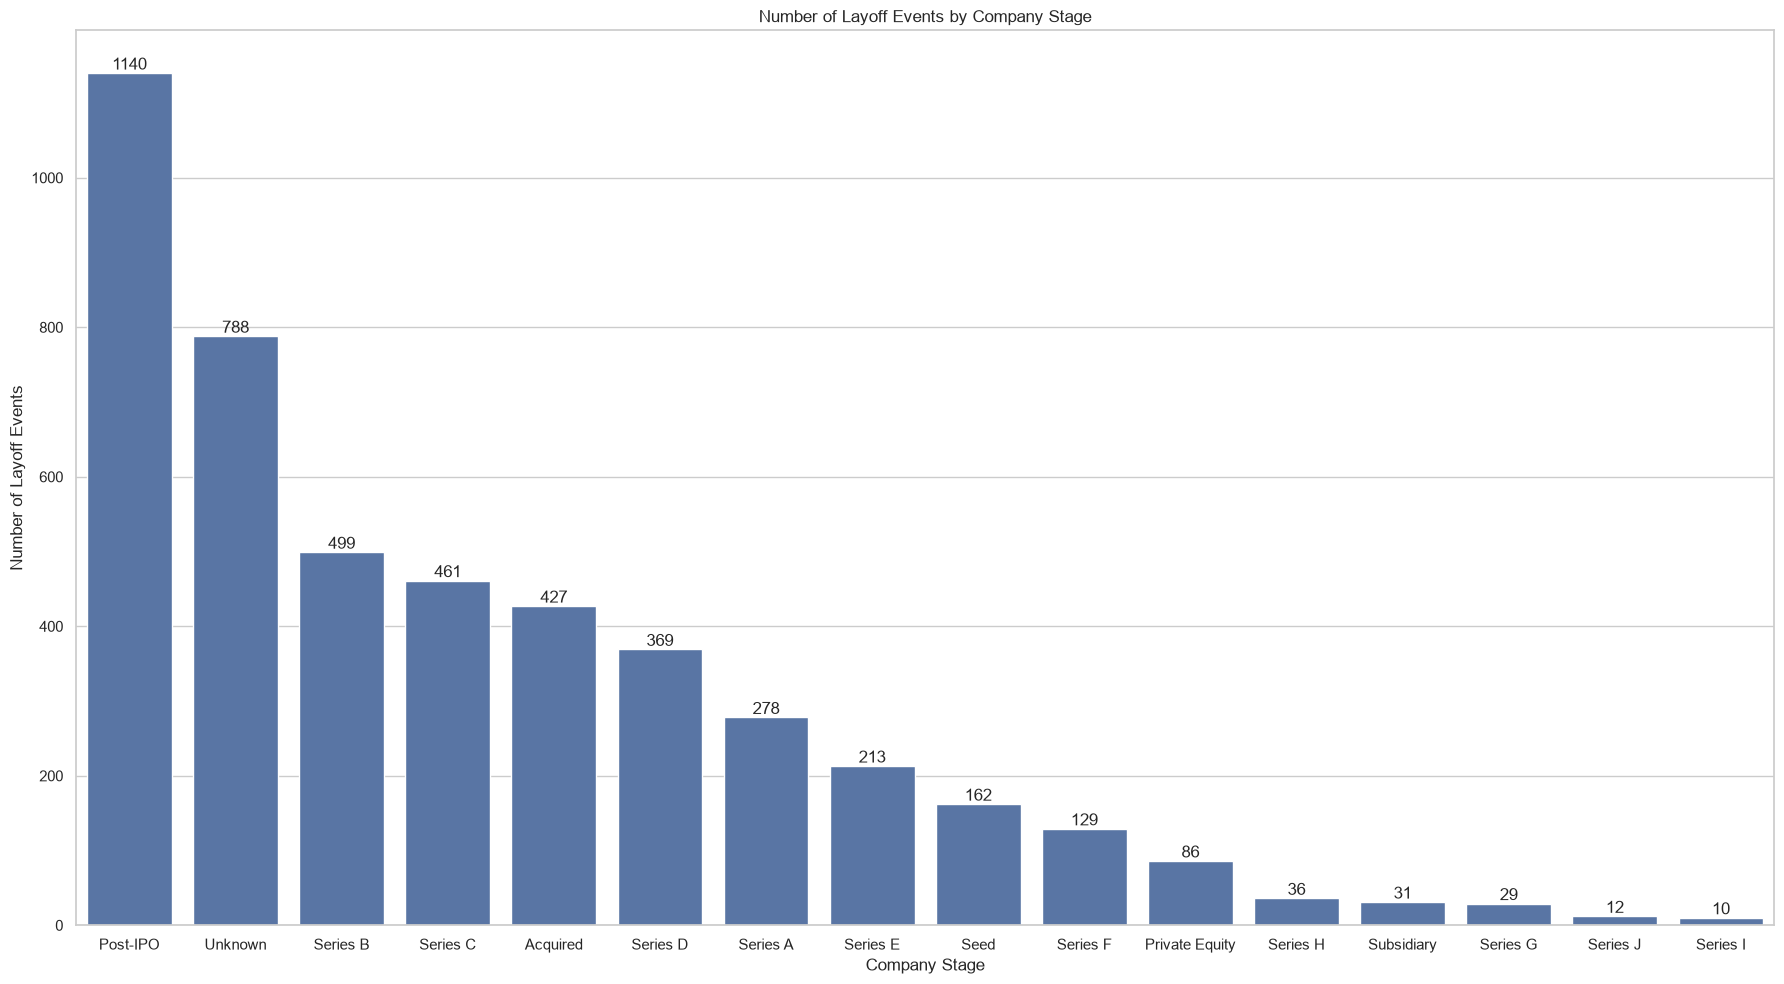

In [429]:
plt.figure(figsize=(18, 10))

ax = sns.barplot(
    data=stage_events,
    x='stage',
    y='total_events'
)

plt.bar_label(ax.containers[0])

plt.title('Number of Layoff Events by Company Stage')
plt.xlabel('Company Stage')
plt.ylabel('Number of Layoff Events')

plt.tight_layout()

plt.savefig('../visualizations/11_layoff_events_by_stage.png',
            dpi=150, bbox_inches='tight')

plt.show()

### Q5. Insights

1. Company stages show differences in their median layoff sizes.
2. The median helps reduce the influence of unusually large layoffs.
3. The number of layoff events and median layoff size measure different things.
4. A stage with more layoff events does not necessarily have a higher median layoff size.
5. The analysis shows an association between company stage and layoffs, but does not prove that company stage causes layoffs.



**Series I** recorded the highest median layoff size, with 300 employees, followed by Series J with 250 employees.

**Seed-stage companies** had the lowest median layoff size, with 29.5 employees.

**Post-IPO companies** recorded the highest number of layoff events, with 1,140 events.

Series I had a higher median layoff size than Post-IPO companies, but Post-IPO companies had significantly more recorded events.

The results show that layoff size and event frequency vary across company stages. Company stage is associated with different layoff patterns, but this analysis does not prove causation.

# Q6. How big were the cuts relative to company size?

This is an important analysis because it tells us how severe the layoffs were relative to each company's workforce.

For example:
- 0.10 = 10% of employees laid off.
- 0.50 = 50% of employees laid off.
- 1.00 = 100% of employees laid off (complete shutdown).

1.What does the distribution of layoff percentages look like?

2.How many records show 100% layoffs?

3.Do some industries have higher shutdown rates than others?

Understand the percentage_laid_off column

In [430]:
df['percentage_laid_off'].describe()

count    2913.000000
mean        0.296822
std         0.307893
min         0.000000
25%         0.100000
50%         0.170000
75%         0.330000
max         1.000000
Name: percentage_laid_off, dtype: float64

In [431]:
df['percentage_laid_off'].isnull().sum()

np.int64(1757)

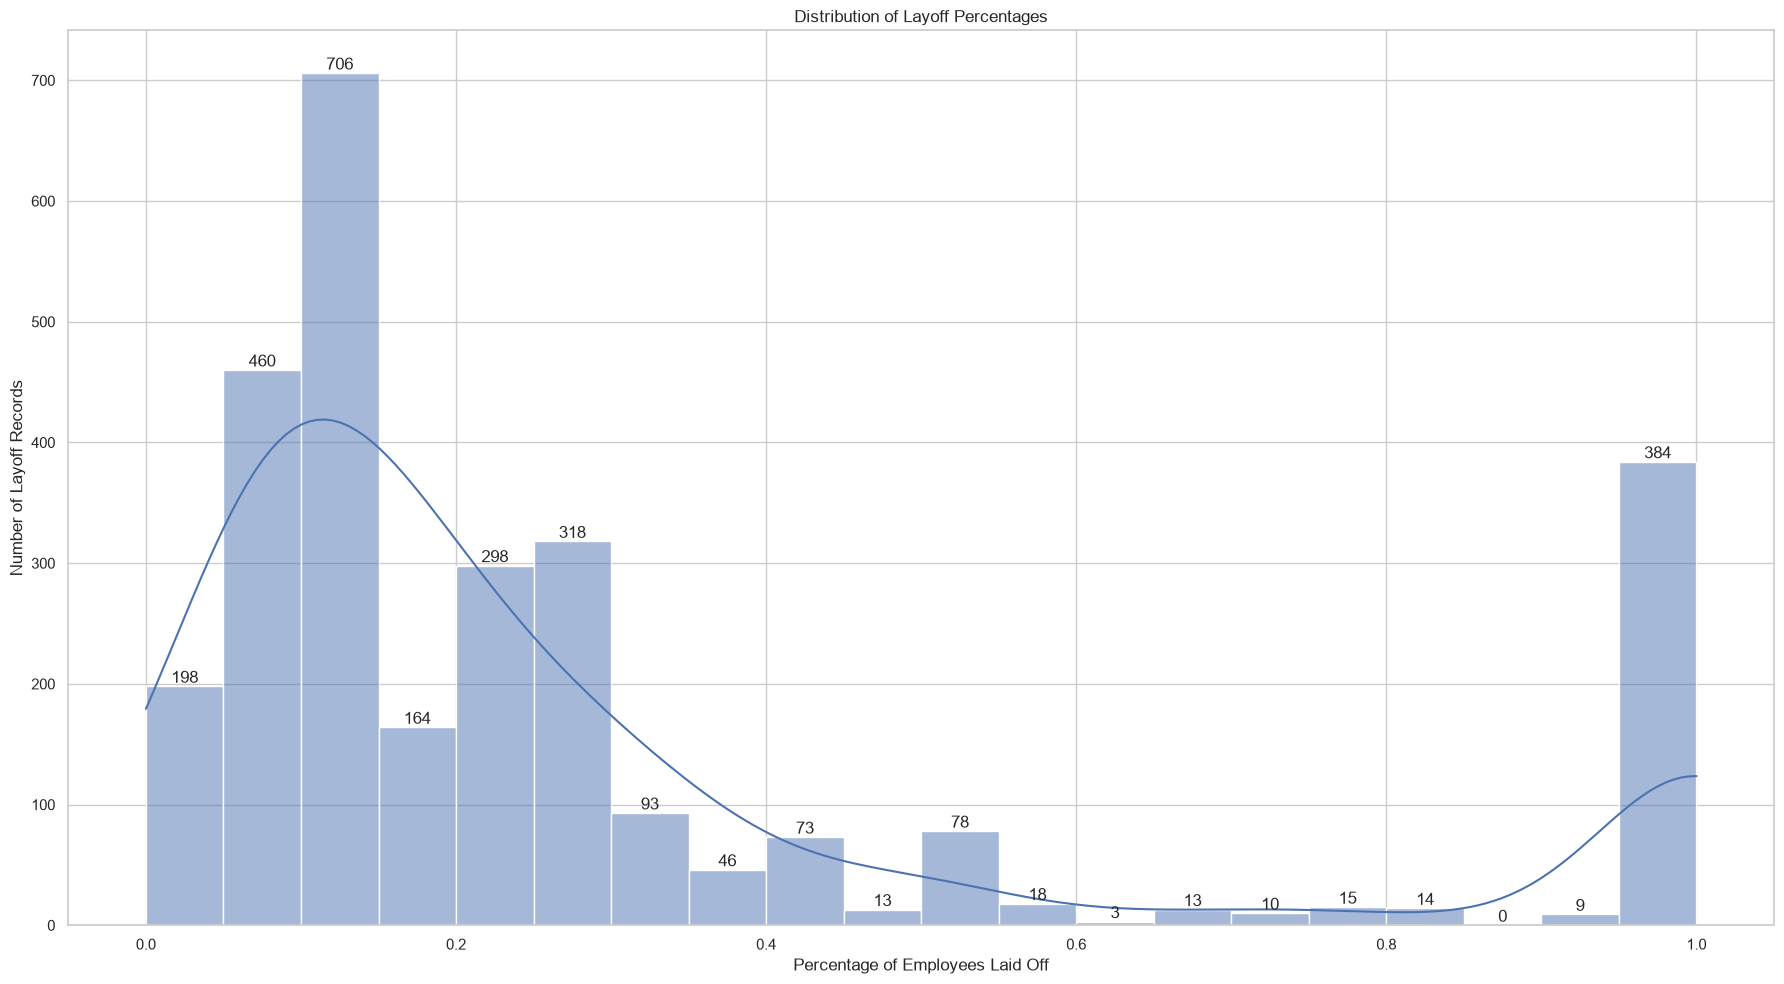

In [432]:
plt.figure(figsize=(18,10))

ax = sns.histplot(
    data=df,
    x='percentage_laid_off',
    bins=20,
    kde=True
)
#bin - bins controls how many groups (intervals) your data is divided into in a histogram.
#kde(Kernel Density Estimation) - It adds a smooth curve over your histogram to show the overall distribution pattern of your data.

plt.bar_label(ax.containers[0])

plt.title('Distribution of Layoff Percentages')
plt.xlabel('Percentage of Employees Laid Off')
plt.ylabel('Number of Layoff Records')

plt.tight_layout()

plt.savefig('../visualizations/12_layoff_percentage_distribution.png',
            dpi=150, bbox_inches='tight')

plt.show()


We chose a histogram because percentage_laid_off is a numerical column, and we want to understand how layoff percentages are distributed across all records.

Count companies that laid off 100% of their employees

In [433]:
shutdowns = df[df['percentage_laid_off'] == 1.0]

shutdowns

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added,size_known,year,month
3,Val Town,New York City,NaN,2026-11-10,1.0,Product,https://blog.val.town/winding-down,Seed,7.0,United States,2026-11-14,False,2026,11
11,Explorium,"Tel Aviv, Non-U.S.",NaN,2026-11-04,1.0,Data,https://www.calcalistech.com/ctechnews/article...,Series C,125.0,Israel,2026-11-07,False,2026,11
20,Ollie,San Diego,NaN,2026-10-30,1.0,Consumer,https://techcrunch.com/2026/10/30/ollie-a-priv...,Seed,7.0,United States,2026-11-02,False,2026,10
43,Character.AI,SF Bay Area,NaN,2026-10-13,1.0,AI,https://www.cnbc.com/2026/10/13/character-ai-c...,Series A,150.0,United States,2026-10-14,False,2026,10
45,YoLa Fresh,"Casablanca, Non-U.S.",NaN,2026-10-12,1.0,Food,https://www.techinafrica.com/moroccan-agritech...,Seed,9.0,Morocco,2026-10-14,False,2026,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4653,Service,Los Angeles,NaN,2020-03-20,1.0,Travel,https://techcrunch.com/2020/03/16/travel-savin...,Seed,5.0,United States,2020-04-01,False,2020,3
4656,Ejento,SF Bay Area,84.0,2020-03-19,1.0,Recruiting,https://layoffs.fyi/list/ejento/,Unknown,NaN,United States,2020-03-28,True,2020,3
4660,Popin,New York City,NaN,2020-03-19,1.0,Fitness,https://www.businessinsider.com/fitness-app-po...,Unknown,13.0,United States,2020-04-06,False,2020,3
4664,Help.com,Austin,16.0,2020-03-16,1.0,Support,LinkedIn,Seed,6.0,United States,2020-04-16,True,2020,3


In [434]:
shutdown_count = len(shutdowns)

shutdown_count

381

Find the companies

In [435]:
shutdowns[['company', 'industry', 'country', 'date', 'percentage_laid_off']]

,company,industry,country,date,percentage_laid_off
3,Val Town,Product,United States,2026-11-10,1.0
11,Explorium,Data,Israel,2026-11-04,1.0
20,Ollie,Consumer,United States,2026-10-30,1.0
43,Character.AI,AI,United States,2026-10-13,1.0
45,YoLa Fresh,Food,Morocco,2026-10-12,1.0
...,...,...,...,...,...
4653,Service,Travel,United States,2020-03-20,1.0
4656,Ejento,Recruiting,United States,2020-03-19,1.0
4660,Popin,Fitness,United States,2020-03-19,1.0
4664,Help.com,Support,United States,2020-03-16,1.0


Which industries have the highest shutdown rates?

Calculate shutdowns by industry

In [436]:
industry_shutdowns = (
    df[df['percentage_laid_off'].notnull()]
    .groupby('industry')
    .agg(
        total_records=('percentage_laid_off', 'count'),
        shutdowns=('percentage_laid_off', lambda x: (x == 1.0).sum())
    )
    .reset_index()
)
#agg - Aggregation is a Pandas method used to perform one or multiple aggregation operations (such as sum, mean, count, min and max) on a Series or DataFrame, often used with groupby() to summarize data.
#lambda x: (x == 1.0).sum() — counts records where 100% of employees were laid off.


Calculate the shutdown rate

In [437]:
industry_shutdowns['shutdown_rate'] = (
    industry_shutdowns['shutdowns'] /
    industry_shutdowns['total_records']
) * 100

In [438]:
industry_shutdowns = industry_shutdowns.sort_values(
    'shutdown_rate',
    ascending=False
)

industry_shutdowns

,industry,total_records,shutdowns,shutdown_rate
1,Aerospace,16,4,25.000000
10,Food,169,42,24.852071
0,AI,25,6,24.000000
2,Construction,17,4,23.529412
7,Energy,32,6,18.750000
6,Education,96,16,16.666667
14,Infrastructure,48,8,16.666667
24,Retail,223,35,15.695067
21,Product,48,7,14.583333
29,Travel,69,10,14.492754


Display the top 10 industries

In [439]:
top_10_shutdown_industries = industry_shutdowns.head(10)

top_10_shutdown_industries

,industry,total_records,shutdowns,shutdown_rate
1,Aerospace,16,4,25.000000
10,Food,169,42,24.852071
0,AI,25,6,24.000000
2,Construction,17,4,23.529412
7,Energy,32,6,18.750000
6,Education,96,16,16.666667
14,Infrastructure,48,8,16.666667
24,Retail,223,35,15.695067
21,Product,48,7,14.583333
29,Travel,69,10,14.492754


Plot shutdown rates by industry

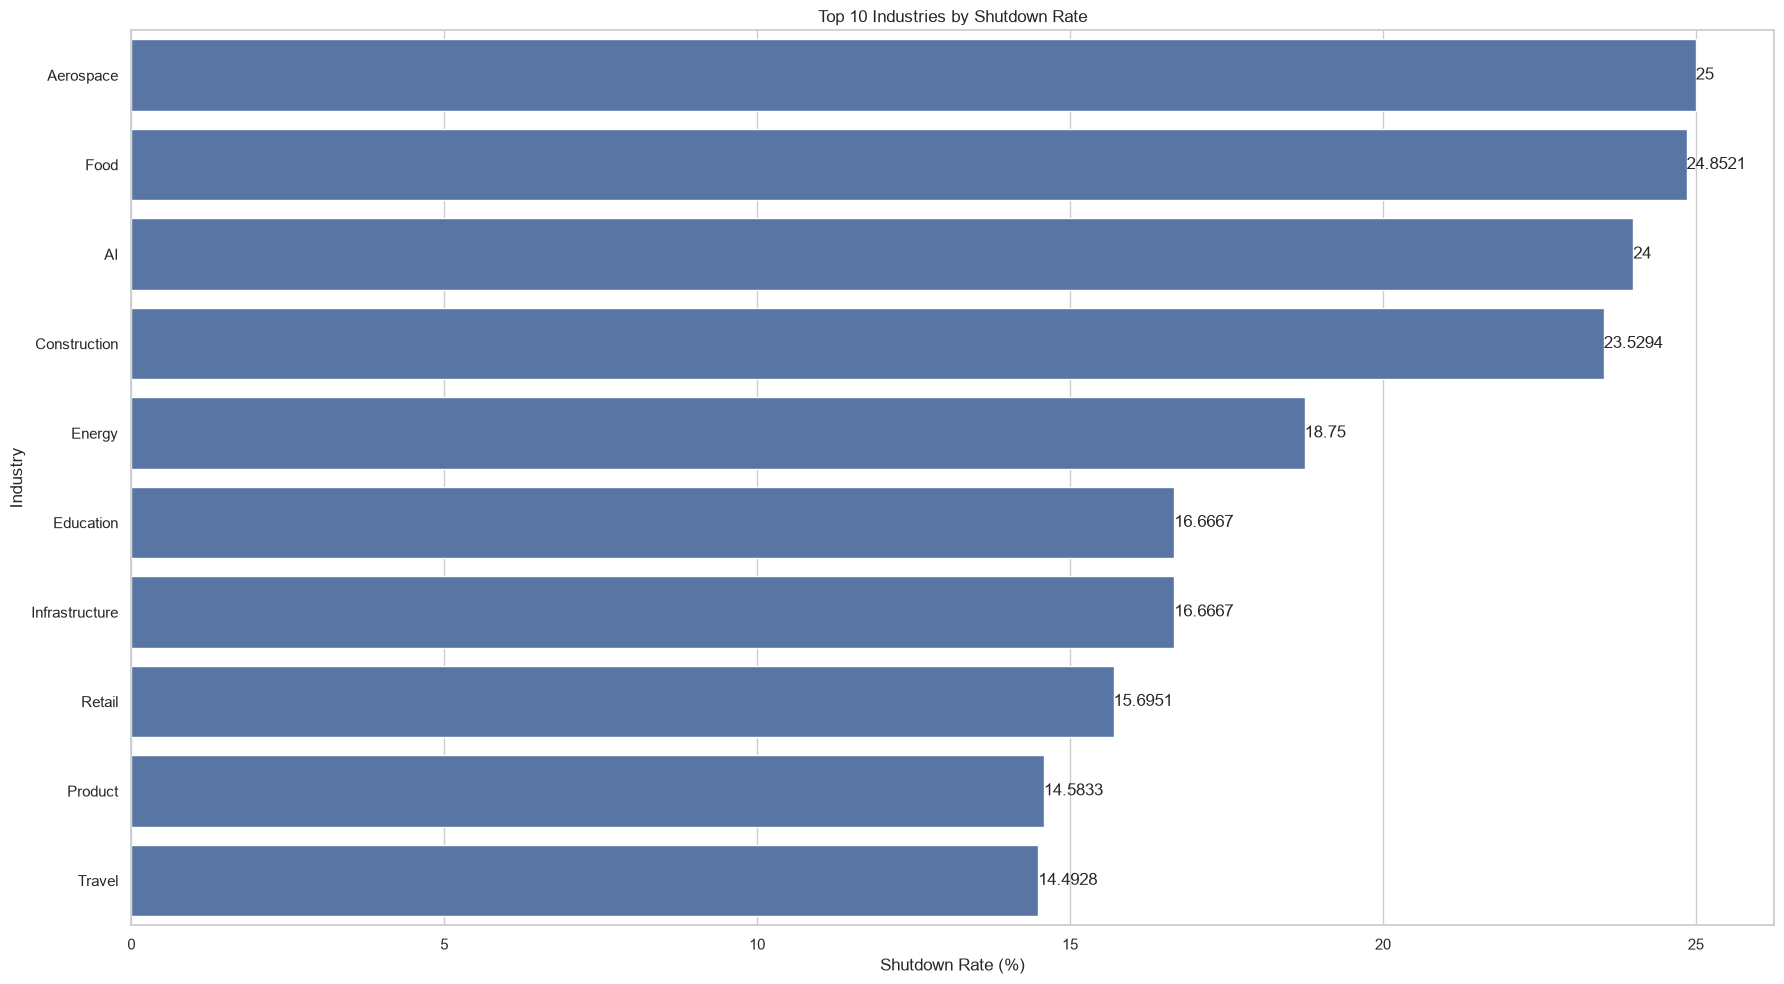

In [440]:
plt.figure(figsize=(18, 10))

ax = sns.barplot(
    data=top_10_shutdown_industries,
    x='shutdown_rate',
    y='industry'
)

plt.bar_label(ax.containers[0])

plt.title('Top 10 Industries by Shutdown Rate')
plt.xlabel('Shutdown Rate (%)')
plt.ylabel('Industry')

plt.tight_layout()

plt.savefig('../visualizations/13_shutdown_rate_by_industry.png',
            dpi=150, bbox_inches='tight')

plt.show()

### Q6. Insights

1. The histogram shows the distribution of layoff percentages across recorded layoff events.
2. A total of **381 shutdown records** were identified, where 100% of the reported workforce was laid off.
3. Aerospace recorded the highest shutdown rate at **25%**, based on 4 shutdowns out of 16 records.
4. Food followed closely with a **24.85%** shutdown rate and had the highest number of shutdown records among the top 10 industries, with 42.
5. AI recorded a **24%** shutdown rate, based on 6 shutdowns out of 25 records.
6. Shutdown rates vary across industries. However, rates based on small numbers of records should be interpreted cautiously.

# Q7. Does funding relate to layoffs?

This is an interesting question because we want to investigate:
Do companies that raised more money also lay off more employees?

We'll compare two numerical columns:
- funds_raised — total funding raised by a company.
- total_laid_off — number of employees laid off.

We'll use:
1. Scatter plot with logarithmic scales on both axes.
2. Correlation using .corr().
3. Interpretation of the relationship.

Prepare the data

In [441]:
funding_layoffs = df[
    ['company', 'funds_raised', 'total_laid_off']
].dropna()

In [442]:
funding_layoffs.shape

(2716, 3)

In [443]:
funding_layoffs.head()

,company,funds_raised,total_laid_off
1,Innoviz,547.0,80.0
7,Bria,66.0,20.0
8,Heidi Health,432.0,108.0
12,Fiserv,3200.0,3000.0
13,Canva,2500.0,1271.0


Understand log scales

need logarithmic scales bcoz The values have a huge range. On a normal scale, smaller values can get compressed near zero.A log scale helps us see both smaller and larger values more clearly.

Create the scatter plot

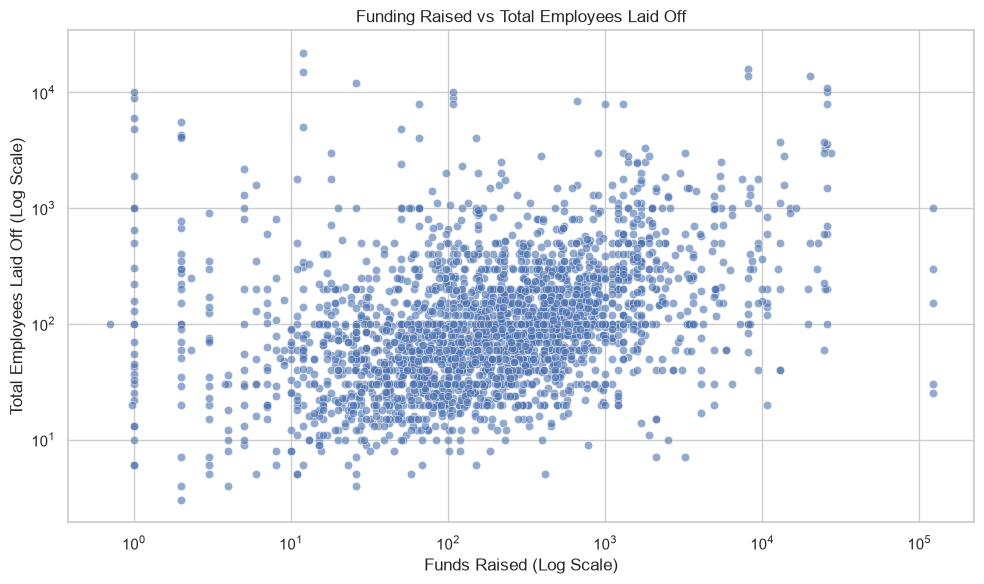

In [444]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=funding_layoffs,
    x='funds_raised',
    y='total_laid_off',
    alpha=0.6
    #alpha=0.6 controls the transparency of the dots
)

plt.xscale('log')
plt.yscale('log')

plt.title('Funding Raised vs Total Employees Laid Off')
plt.xlabel('Funds Raised (Log Scale)')
plt.ylabel('Total Employees Laid Off (Log Scale)')

plt.tight_layout()

plt.savefig('../visualizations/14_funding_vs_layoffs.png',
            dpi=150, bbox_inches='tight')

plt.show()

Calculate correlatio

In [445]:
funding_layoffs[['funds_raised', 'total_laid_off']].corr()

,funds_raised,total_laid_off
funds_raised,1.000000,0.119109
total_laid_off,0.119109,1.000000


.corr() calculates the Pearson correlation by default

Interpret the correlation honestly


funds_raised	  total_laid_off

funds_raised	  1.000000	  0.119109

total_laid_off	  0.119109	  1.000000


### Q7. Insights: Does Funding Relate to Layoffs?

1. The scatter plot compares the amount of funding raised by companies with the number of employees laid off.
2. The Pearson correlation coefficient is **0.1191**, indicating a very weak positive linear relationship.
3. This suggests that companies with higher funding do not necessarily lay off more employees.
4. Funding raised alone does not explain the variation in layoff numbers. Other factors, such as company size, financial performance, and business conditions, may also influence layoffs.
5. Correlation does not imply causation, so we cannot conclude that funding levels cause layoffs.

# Q8. Which months or seasons have the most layoffs?

We'll use only full years from 2021 to 2025. This avoids comparing incomplete years

Filter the data

In [446]:
seasonal_df = df_size[
    df_size['date'].dt.year.between(2021, 2025)
].copy()

In [447]:
seasonal_df['date'].dt.year.value_counts().sort_index()

date
2021     31
2022    818
2023    848
2024    388
2025    227
Name: count, dtype: int64

Group by month

In [448]:
month_of_year_layoffs = (
    seasonal_df.groupby(seasonal_df['date'].dt.month)['total_laid_off']
    .sum()
    .reset_index()
)

In [449]:
month_of_year_layoffs.columns = ['month', 'total_laid_off']
month_of_year_layoffs

,month,total_laid_off
0,1,133706.0
1,2,76758.0
2,3,60041.0
3,4,72132.0
4,5,49700.0
5,6,42723.0
6,7,52707.0
7,8,57496.0
8,9,19239.0
9,10,51691.0


Create the bar chart

In [450]:
import calendar

month_of_year_layoffs['month_name'] = month_of_year_layoffs['month'].apply(
    lambda x: calendar.month_name[x]
)

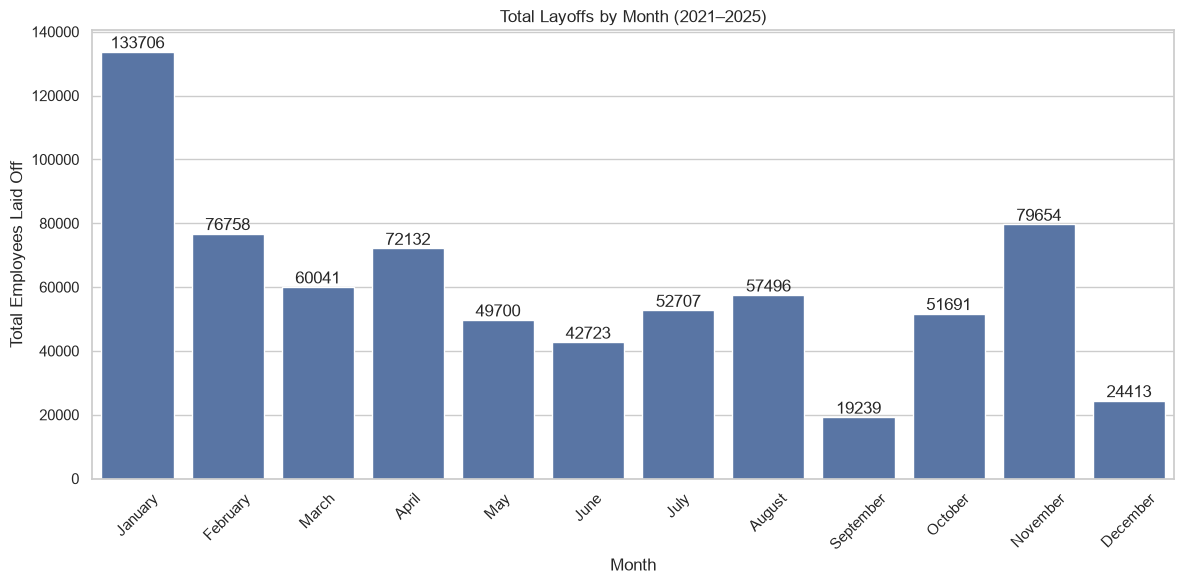

In [451]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=month_of_year_layoffs,
    x='month_name',
    y='total_laid_off'
)

plt.bar_label(ax.containers[0])

plt.title('Total Layoffs by Month (2021–2025)')
plt.xlabel('Month')
plt.ylabel('Total Employees Laid Off')

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../visualizations/15_layoffs_by_month.png',
            dpi=150, bbox_inches='tight')

plt.show()

Identify the highest and lowest months

In [452]:
month_of_year_layoffs.loc[
    month_of_year_layoffs['total_laid_off'].idxmax()
]

month                    1
total_laid_off    133706.0
month_name         January
Name: 0, dtype: object

In [453]:
month_of_year_layoffs.loc[
    month_of_year_layoffs['total_laid_off'].idxmin()
]

month                     9
total_laid_off      19239.0
month_name        September
Name: 8, dtype: object

Create a year-by-month table

In [454]:
year_month_data = seasonal_df.assign(
    year=seasonal_df['date'].dt.year,
    month=seasonal_df['date'].dt.month
)

year_month_pivot = year_month_data.pivot_table(
    index='year',
    columns='month',
    values='total_laid_off',
    aggfunc='sum',
    fill_value=0
)

year_month_pivot

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2021,6813.0,868.0,47.0,261.0,0.0,2434.0,80.0,1867.0,161.0,22.0,2070.0,1200.0
2022,510.0,3685.0,5714.0,4128.0,12985.0,17394.0,16238.0,13055.0,5881.0,20471.0,53524.0,10664.0
2023,89709.0,40002.0,37963.0,20100.0,15127.0,11206.0,10690.0,10178.0,4707.0,8176.0,8373.0,8429.0
2024,34137.0,15729.0,7403.0,22423.0,11011.0,10083.0,9051.0,25944.0,4036.0,3782.0,6755.0,2568.0
2025,2537.0,16474.0,8914.0,25220.0,10577.0,1606.0,16648.0,6452.0,4454.0,19240.0,8932.0,1552.0


Find the top three months in each year

In [455]:
top_3_months_each_year = year_month_pivot.apply(
    lambda row: row.nlargest(3).index.tolist(),
    axis=1
)

top_3_months_each_year

year
2021     [1, 6, 11]
2022    [11, 10, 6]
2023      [1, 2, 3]
2024      [1, 8, 4]
2025     [4, 10, 7]
dtype: object

Count how many years January appears in the top three

In [456]:
january_top_3_count = sum(
    1 for months in top_3_months_each_year
    if 1 in months
)

print("Number of years January ranked in the top 3:",
      january_top_3_count)

Number of years January ranked in the top 3: 3


### Q8. Insights: Which Months Have the Most Layoffs?

1. January recorded the highest combined layoffs across 2021–2025, with 133,706 employees.
2. November recorded the second-highest total, with 79,654 layoffs, followed by February with 76,758.
3. September recorded the lowest total, with 19,239 layoffs.
4. January 2023 alone contributed 89,709 layoffs, approximately 67.1% of all January layoffs across the five-year period.
5. Therefore, January's highest overall ranking is heavily influenced by January 2023 and does not, by itself, establish a consistent seasonal pattern.